# AI 활용에 관하여

과제는 AI 를 사용할 것을 전제로 만들어지고 있습니다.
하지만, 학습의 효율성을 위해서 무분별한 AI 사용은 권장드리지 않고 있어요.

따라서, AI 를 피어리뷰어로서 생각하고 사용해주시는 것을 권고드립니다.  
이를 판단할 수 있는 하나의 기준으로는 같은 수업을 듣는 다른 친구에게 물어볼 수 있는 질문인가? 라고 스스로 물어보는 것도 좋은 기준이 될 수 있을 것 같습니다.

아래는 이에 대한 몇가지 예시입니다.


> AI 사용 가능:
> - 문법 및 API 확인
> - 오류 메시지 해석
> - 실행 환경 문제 해결
> - 내가 작성한 설명의 반례 요청

> AI에 맡기지 않을 것:
> - 실행 전 예측
> - 실행 결과에서 근거 선택
> - 의견 및 선택의 최종 판단

# 5주차 과제: NLP의 역사

이번 5주차부터는 새로운 도메인으로서 자연어처리를 학습하게 됩니다.  
최신 알고리즘과 아키텍처를 학습하기 전에, 어떤 방법을 사용해왔는지, 자연어처리란 무엇인지 공부해봅시다.

이를 위해 기존의 방식에서 어떤 한계점을 발견했고, 후속 방식이 어떻게 해결했나에 집중해봅시다.

**필수 범위**
- 언어 도메인의 기본 성질과 입력 단위에 관한 질문(Q1~Q2)
- N-gram, RNN, LSTM & GRU, seq2seq, attention의 문제 해결 흐름(Q3~Q7)
- Keras로 같은 문제를 푸는 세 모델의 비교 관찰(Q8~Q11)
- 이번 주 정리와 남은 질문(Q12)


## 목차

1. [언어라는 도메인](#language-domain) (Q1~Q2)
2. [문맥을 통계적으로 다루기: N-gram](#ngram) (Q3)
3. [순서를 따라 정보를 전달하기: RNN](#rnn) (Q4)
4. [무엇을 기억하고 갱신할까: LSTM & GRU](#gates) (Q5)
5. [시퀀스에서 시퀀스로: Seq2seq와 Attention](#seq2seq) (Q6~Q7)
   - [Attention: 필요할 때 입력 표현을 다시 참조하기](#attention)
6. [같은 문제로 RNN & LSTM & GRU 비교하기](#comparison) (Q8~Q11)
   - [문제: 마지막 색 지시 기억하기](#color-task)
   - [Keras로 공통 모델 만들기](#keras-model)
   - [모델 비교하기](#observe)
   - [Test와 거리별 결과 확인하기](#test-results)
7. [마무리](#wrap-up)

[참고자료](#references)


## 실행 환경

- 저장소 루트 또는 `week5` 폴더에서 노트북을 열어주세요.
- `week5_support.py`는 데이터 생성 & 자기점검 & 학습 & 시각화를 위한 제공 코드입니다.
  내부 구현을 이해하거나 수정하는 것은 필수가 아닙니다.
- 같은 seed라도 실행 환경과 라이브러리 버전에 따라 결과가 달라질 수 있습니다.

In [1]:
from pathlib import Path
from copy import deepcopy
import os
import sys
import tempfile

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "deep_learning_week5_mpl"))
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
WEEK5 = Path.cwd()
if not (WEEK5 / "week5_support.py").is_file():
    WEEK5 = WEEK5 / "week5"
if not (WEEK5 / "week5_support.py").is_file():
    raise RuntimeError("저장소 루트 또는 week5 폴더에서 노트북을 열어주세요.")
sys.path.insert(0, str(WEEK5.resolve()))

import numpy as np
import tensorflow as tf
from tensorflow import keras
from week5_support import (
    TOKENS, DEFAULT_CONFIG, configure_runtime,
    make_data, check_data, show_data_summary, show_sequence_pair,
    check_model_builder, train_comparison, plot_learning_curves,
    show_training_summary, evaluate_comparison, show_test_summary,
    show_prediction_pair, show_reference_summary,
)
configure_runtime()
print("TensorFlow:", tf.__version__, "/ Keras:", keras.__version__)
print("이번 노트북:", WEEK5.resolve())

TensorFlow: 2.21.0 / Keras: 3.15.1
이번 노트북: C:\Users\USER\project\deep-learning-study\week5


<a id="language-domain"></a>
# 1. 언어라는 도메인

3주차에서 이미지를 다루기 시작하면서 이미지 자체에 대해 공부해본 것처럼, 자연어의 특성을 알아봅시다.  

저희의 목적은 자연어를 특정 규칙에 따라 숫자의 모음(벡터) 로 바꿔야합니다.  
신경망은 숫자를 계산하는 함수이기 때문입니다.

## 이미지 vs 자연어

이미지를 벡터로 바꾸는 문제는 상대적으로 쉽습니다.  
이미 컴퓨터에서 RGB 라는 값으로 잘 표현되어있기 때문입니다.  
그렇기 때문에 이미지 분야에서는 이 RGB 값을 잘 **"계산"** 하는 방법에 집중하게 됩니다.

자연어 역시 컴퓨터에서 표현되지만, 그대로 사용하기엔 문제가 있습니다.

* "A" = 65
* "B" = 66
* "C" = 67

이게 어떤 의미인지 눈치채셨나요? ASCII 코드입니다.  
컴퓨터는 ASCII 를 통해 언어를 표현하지만, 이것을 자연어처리에 사용하기에는 무리가 있습니다.

> "B" - "A" = 1 ??

ASCII 는 말그대로 표현하기 위한 임의의 값을 사용하기 때문에 어떤 의미를 담지 못합니다.  
이는 이미지의 RGB 값이 다르면 그만큼 색이 실제로 달라지는 것과는 대조적입니다.  

이러한 이유로, 자연어는 먼저

* 어떻게 숫자로 표현할지,
* 표현된 숫자에 어떤 연산을 할지

를 고려해야합니다.  
고려해야할 대표적인 특성이 무엇이 있는지 하나씩 살펴봅시다.  

## 언어의 한계

내용은 안 가벼울 수 있으나, "언어의 한계" 파트는 이해하지 않아도 과제를 진행하는 것에는 큰 문제가 없습니다.  
가볍게 워밍업으로 읽어봅시다. 읽으면서 자연어라는 것이 꽤나 복잡하구나 를 느끼면 좋겠습니다.

20세기에 어떤 철학자가 다음과 같은 말을 했습니다.  
> **"내 언어의 한계는 내 세계의 한계이다."** -비트겐슈타인

이는 사람은 자신이 표현할 수 있는 정도만 세계를 표현할 수 있다는 의미입니다.  
예를 들어, 평생 파란색만 보고 온 남자를 떠올려봅시다.  
그 남자에겐 파란색 외의 색은 존재하지 않습니다. 그 남자에게는 "색" 이라는 개념도, "파란색" 이라는 단어도 존재하지 않게 됩니다.  
모두 동일하니까요.  

반대로, 눈이 많이 내리는 스코틀랜드에서는 "눈" 을 표현하는 단어가 400개가 넘는다고 합니다.  

---

이번엔 문법체계, 즉 문장을 살펴봅시다.  
다음의 2개의 문장을 비교해봅시다.  

* "나는 사과를 좋아한다."
* "I like apples"

이 간단한 두 문장에서조차, 서로 다른 문법을 보입니다.  
행동의 주체인 주어 다음에, 대상(목적어)가 혹은 동작(동사)가 올 수 있습니다.

이러한 문법체계는 실제로 사람의 사고방식에 영향을 끼친다는 인지과학 결과도 존재합니다.(언어 상대성 이론)  

이런 이론을 떠나더라도, 국어에는 도치법 등의 구조를 비트는 표현방식이 존재합니다.  
그 비틀어진 구조 자체에도 어떤 의미가 내포되어있는 것입니다.

이처럼 자언어는 그 자체로 복잡 미묘한 대상이라고 볼 수 있습니다.  

## 단어를 벡터로 바꾸기

이번에는 단어를 구체적으로 숫자, 즉 벡터로 바꾸는 방법에 대해 살펴봅시다.  

### One-Hot Encoding

One-Hot Encoding 은 일종의 단어 사전을 가지게 됩니다.  
각 단어는 고유의 index 를 가지게 됨으로서 단어는 단어 사전 크기의 벡터를 가지며, 본인의 index 위치의 값을 1로 가집니다.

예를 들어, "apple" = [0, 0, 0, 0, 0, 0, **1**, 0, 0, 0] 이라고 한다면,  
apple 은 10개의 단어 중 7번째를 의미합니다.  
하지만, 이 방식은 ASCII 와 같은 이유로 이웃 단어인 "car" 와는 연관성이 없어보입니다.

그래서 해당 Encoding 방식을 활용하여 다른 Embedding 방식을 사용하게 됩니다.

**Q-Extra.** Encoding 과 Embedding 은 비슷한 표현처럼 들리지만, 미묘한 차이점이 있습니다. 이에 대해 조사해봅시다.  
**Q-Extra.** 가장 먼저 떠오르는 방식은 띄어쓰기 단위로 문장을 나누는 것입니다. 이 방식의 단점은 없을까요?  
다른 방식은 없을까요? 이에 대해 생각해보고, BPE(Byte-Pair Encoding) 을 찾아봅시다.

### Learned Embedding

주어진 단어(one-hot encoding 된 단어) 를 문제에 맞는 적절한 저차원의 벡터로 변환합니다.  
이 변환 과정에 신경망을 사용하여, 문제에 맞는 벡터로 변환하도록 학습합니다.  

"apple" = [0, 0, 0, 0, 0, 0, **1**, 0, 0, 0] 의 경우는,  
[0.2, 0.1, 0.3] 등으로 변하는 것을 예시로 들 수 있습니다.

여기까지 단어 자체에 집중하여 벡터로 바꾸는 과정을 살펴보았습니다.  
하지만, 단어의 의미는 단어 그 자체가 아닌, 맥락과 순서에 의해서도 표현됩니다. 이에 대해 알아봅시다.

## 단어의 의미는 주변에서 정해진다

이번엔 다음의 문장을 살펴봅시다. "배" 의 의미에 집중해서 읽어봅시다.

* 어제 마트에서 달고 시원한 **배** 를 샀다.
* 점심을 너무 많이 먹었더니 **배** 가 부르다.
* 우리는 제주도로 가기 위해 큰 **배** 에 올라탔다.

위의 3개의 문장에는 같은 "배" 라는 표현이 있지만, 그 의미는 모두 다릅니다.  
그 의미는 단어 자체에서 결정되는게 아닌, 문맥 즉 주변 단어에 의해 결정됩니다.  

이를 처리하기 위해서 과거에는 "N-gram" 즉, 최근 N개의 단어를 바탕으로 다음 단어를 추론하는 방식이 사용되곤 했습니다.  
현대에는 스터디 시간에 배운 RNN, LSTM, GRU, Attention 등의 방법으로 이 특성을 처리하게 됩니다.  
이 4가지 방법은 각자의 방법으로 주변 단어로부터 맥락을 얻어오게 됩니다.

## 단어의 순서에도 의미가 존재한다

다시 한번, 두 문장을 살펴봅시다.  

* Alice hits Bob
* Bob hits Alice

사용된 단어는 동일하지만, 그 의미는 완전히 달라집니다.  
순서에 따라서 사과를 해야할 사람이 달라질겁니다.  

이번엔 다른 2개의 문장을 살펴봅시다.

* 나는 찬란한 슬픔의 봄을 아직 기다리고 있을 테요.
* 나는 아직 기다리고 있을 테요, 찬란한 슬픔의 봄을.

위와 같이 순서를 바꾼 것만으로 의미가 추가되기도 합니다.  

이에 저희는 단어를 Embedding 할 때, 그 숫자 자체가 단어에 대한 의미(정보) 를 담기게 할 뿐 아니라,  
현재 위치, 순서에 대한 정보가 담기길 원하게 됩니다.  

이를 처리하는 방법 중 하나를 "Positional Encoding" 이라고 합니다.  
즉, Embedding 된 Vector 에 위치 정보를 추가해주는 것입니다.

이를 처리하는 가장 간단한 방식은,  
순차적으로 index 를 부여하는 것일겁니다.  

"Alice hits Bob" 에 대해 순서대로, 0, 1, 2 를 부여할 수 있습니다.  
하지만, 문장이 가변적이고 정규화가 힘들기 때문에 다른 방식을 사용합니다.  
(정규화가 되지 않는다면, 단어 자체에 대한 벡터에 비해 위치 정보가 지배적이게 됩니다. ex. 0.32 + index 100)  

대표적으로는 $sin$, $cos$ 을 사용하는 Sinusoidal Encoding 을 사용하게 됩니다.  
이 방식은 위치정보에 대한 일정 수준 이상의 정확도와 문장의 길이에 무관하게 값을 가진다는 특징을 가집니다.

**Q1.** Keras 의 2가지 Encoding Layer 를 확인해보고 어떻게 사용하는지 정리해봅시다.  
추가로, positional, sine-positional 이 어떻게 다른지 찾아보고 정리해봅시다.

**HINT: sine-positional 은 위치를 여러 sin 함수의 합으로 나타냅니다.**  
**사실 모든 함수는 sin 혹은 cos 으로 표현할 수 있습니다.**  
**신호처리분야 등에서는 Fourier Transform 이라는 방법을 자주 쓰곤합니다.**  
**이 부분은 꽤 어려운 내용이기 때문에 LLM 의 도움을 적극적으로 받아봅시다.**

* https://keras.io/keras_hub/api/modeling_layers/position_embedding/
* https://keras.io/keras_hub/api/modeling_layers/sine_position_encoding/

**Keras의 PositionEmbedding과 SinePositionEncoding은 모두 순차 데이터에 위치 정보를 제공하기 위한 레이어다.
PositionEmbedding은 위치마다 학습 가능한 벡터를 할당하여 데이터에 적합한 위치 표현을 학습한다. 반면 SinePositionEncoding은 서로 다른 주파수의 sin과 cos 함수를 결합해 위치 정보를 계산하므로 추가적인 학습 파라미터가 필요하지 않다.
두 방법 모두 Transformer가 단어의 순서를 고려하도록 돕지만, 위치 정보를 학습을 통해 얻는지, 수학적으로 계산하는지가 가장 큰 차이점이다.**

**Q2.** 지금까지 이야기한 언어의 특성을 각자의 방식으로 정리해봅시다.  
여기서 이야기하지 않은 언어의 특성은 또 무엇이 있을까요? 아래는 생각해볼만한 질문입니다.

* 한국어에는 보조사를 통해서도 의미를 전달하곤 합니다.  
  보조사가 다른 명사나 동사와는 어떻게 다르고, 그 점이 단어 단위 Encoding 에 어떤 영향을 줄까요?
* 한글에는 조사를 통해 의미를 명확하게 하곤 합니다.  
  예를 들어 조사를 사용하면 순서가 달라져도 같은 의미를 전달할 수도 있습니다.
* "is", "are", "be" 같은 단어는 동일한 의미를 가지는데 다른 단어로 처리해야할까요?  
* 꼭 단어 단위로 나눠야할까요? 알파벳 단위는 어떨까요? 다른 단위는 없을까요?  
    * "strongest", "weakest", "disagree", "dislike" 를 살펴봅시다. (접두사, 접미사라고도 하죠)

**자연어는 문법적 구조, 의미적 관계, 문맥 의존성, 순서, 형태 변화, 다양한 구성 단위, 장거리 의존성, 중의성 등의 특징을 가진다. 이러한 요소들이 복합적으로 작용하기 때문에 언어의 의미는 개별 단어만으로 결정되지 않고 단어들 사이의 관계와 전체적인 맥락 속에서 형성된다.**

<a id="ngram"></a>
# 2. 문맥을 통계적으로 다루기: N-gram

이번엔 다음 문장의 빈칸에 어떤 단어가 들어갈지 생각해봅시다.

> 나는 오늘 학교에 ___

"간다", "갔다" 등의 단어가 먼저 떠오를 겁니다.  
앞의 단어들을 보고, 그 뒤에 자연스럽게 이어질 단어를 생각했을 듯합니다.  

> "앞의 단어를 통해 다음 단어를 예측해보겠다."

이를 시도하는 가장 기초적인 방법은 기존의 데이터로부터 얼마나 자주 발생했는지 살펴보는 것입니다.

많은 문장을 모은 자료를 **말뭉치(corpus)** 라고 합니다.  
말뭉치에서 "학교에 간다"가 3번, "학교에 갔다"가 1번 등장했다고 해봅시다.  
이 자료에서는, "학교에" 다음에 "간다"가 올 확률을 3/4, "갔다"가 올 확률을 1/4로 둘 수 있습니다.

이처럼 앞의 단어들을 참고하여 다음 단어의 확률을 구하는 방법 중 하나가 **N-gram 언어 모델**입니다.  
여기서 $N$ 은 모델이 살펴보는 단어의 개수로, 모델이 살펴볼 수 있는 문맥의 최대라고 할 수 있습니다.

예시를 살펴봅시다.

| 모델 | "나는 오늘 학교에 ___"에서 참고하는 범위 |
|---|---|
| Bigram | `학교에` |
| Trigram | `오늘 학교에` |

Trigram 의 경우, "오늘 학교에" 가 등장한 빈도 대비 "오늘 학교에 _" 가 올 확률을 구한 다음,  
주어진 확률 분포에 맞게 랜덤하게 선정합니다.  

예를 들어, "지각했다" 라는 단어가 0.3의 확률로 선정되었다는 건,  
10개의 "오늘 학교에 _" 의 예시에서 "오늘 학교에 지각했다" 가 3번 등장했다고 이해할 수 있습니다.

앞 절에서는 주변 문맥에 따라 단어의 의미를 해석할 수 있다는 점을 보았습니다.  
이와 관련하여, **비슷한 문맥에 등장하는 단어는 의미도 관련될 수 있다**는 관점을 분포 가설이라고 합니다.  

N-gram 은 "분포 가설" 을 데이터의 통계를 통해 실현했다고 볼 수 있습니다.  
하지만, 통계적인 접근은 많이 부족하다는 생각이 들게 됩니다.  
맥락을 고려하고 싶다는 이야기가 "앞에 등장한 단어로부터 통계적으로 구하는 것" 을 의미하는 것은 아니기 때문입니다.  
이전의 단어로부터 어떤 의미를 추출하고, 이를 바탕으로 추론, 적절한 단어를 선택하는 과정을 모사했다고 하기엔 그 간극이 꽤 크게 느껴집니다.  

## N-gram 의 한계점

다음 문제를 위해서, 문제를 한정해봅시다.  

단순히 필요한 단어가 $N$ 보다 길면 어떨까요?  
문단 단위에서 빈칸을 채우기 위한 단어가 5문장 뒤에 있다면, **30**-gram 정도는 필요할 듯합니다.  
하지만, n-gram 이 사용되던 시절에도, 검색엔진을 가지고 있는 구글조차 5-gram 정도가 한계였다고 합니다.  

또는, 수많은 데이터에도 불구하고 그 데이터에 없는 단어를 요구한다면 어떻게 될까요?  
통계적으로 count 가 0 이기 때문에 사전에 구한 데이터에 없는 단어는 등장할 수 없다는 약점 또한 존재합니다.

---

이런 한계점에 문맥을 좀 더 잘 고려할 수 있는 방법을 찾고자 했고, 그 시도가 RNN 입니다.

**Q3.** 다음 두 문장에서 빈칸에 들어갈 단어를 살펴봅시다.

```text
The key near the windows ___ old.   → is
The keys near the windows ___ old.  → are
```

마지막 두 token인 `the windows`만 참고한다면, 두 문장을 구분할 수 있을까요?  
어떤 정보를 더 참고해야 하는지 설명해봅시다.  
추가로, 참고하는 문맥을 계속 늘린다면 필요한 자료의 양에는 어떤 부담이 생길지 정리해봅시다.

* 정해진 데이터에 대해서, $N$ 의 크기를 늘리면 어떻게 될까요?  
* 저장된 데이터로부터 다음 단어를 예측하기 위해서는 각 단어에 대한 등장 확률을 구해야합니다.  
  * 그 확률은 어떻게 구하고, 연산량이 어떻게 될까요?

참고자료: https://youtu.be/fyc0Jzr74y4?si=cNI-53fQ2xViko-f&t=1713


**N-gram은 가까운 단어들의 관계를 이용해 다음 단어를 예측하는 방법이다. 그러나 주어와 동사처럼 멀리 떨어진 단어 사이의 관계를 파악하려면 더 긴 문맥을 참고해야 한다.
이때 N이 증가하면 가능한 단어 조합이 기하급수적으로 늘어나 저장 공간과 학습 데이터에 대한 부담이 커지며 데이터 희소성 문제도 심해진다.
따라서 문맥을 단순히 더 많이 저장하는 것만으로는 언어의 복잡한 관계를 효율적으로 학습하기 어렵다. 이러한 한계를 극복하기 위해 RNN, LSTM, GRU와 Attention처럼 문맥 정보를 학습하고 활용하는 신경망 기반 방법들이 사용된다.**


<a id="rnn"></a>
# 3. 순서를 따라 정보를 전달하기: RNN

앞의 예시에서는 정답을 결정하는 단어가 참고 범위 밖에 있었습니다.  
그렇다면 앞에서 읽은 정보를 다음 단어를 읽을 때도 사용할 수는 없을까요?

예를 들어, "나는 사과를 좋아한다"를 한 단어씩 읽는다고 해봅시다.  
"사과를"을 읽을 때, 앞에서 "나는"을 읽었다는 정보도 함께 사용할 수 있다면 좋을 겁니다.  
그 결과를 다시 다음 단어를 읽는 과정에 전달해보는 것입니다.

이렇게 이전까지 읽은 정보를 상태로 만들어 다음 시점으로 전달하는 구조가 **RNN(Recurrent Neural Network)** 입니다.  
이 상태를 **hidden state(은닉 상태)** 라고 부릅니다.

아래 GIF에서 단어를 하나씩 읽으면서 어떤 값이 만들어지고 전달되는지 살펴봅시다.

<img src="./imgs/rnn_memory.gif" width="1000" alt="나는, 사과를, 좋아한다를 차례로 읽으며 같은 가중치로 hidden state를 계산하고 전달하는 RNN 애니메이션">

현재 단어의 벡터와 이전 상태가 만나 새로운 상태를 만듭니다.  
이 계산을 식으로 나타내면 다음과 같습니다.

$$h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$$

* $x_t$: 현재 token의 벡터 표현
* $h_{t-1}$: 이전까지 읽은 정보가 반영된 상태
* $h_t$: 현재 입력까지 반영하여 만든 새로운 상태

여기서 입력과 상태는 매번 달라지지만, **$W_x$, $W_h$, $b$는 모든 시점에서 같은 값을 사용합니다.**  
3주차에서 이미지의 여러 위치에 같은 kernel을 적용했던 것과 유사하다고 볼 수 있습니다.

1주차에 배운 순전파를 시간 순서대로 이어 붙인 모습이기도 합니다.  
입력이 길어져도 같은 계산을 반복하면서 앞의 정보를 상태에 반영할 수 있습니다.  
단, hidden state에는 입력 전체를 그대로 저장하는 대신, 문제를 풀 때 필요한 정보가 담기도록 학습합니다.

## 모든 정보를 동등하게 전달해야 할까요?

"빨강"이라는 지시를 읽고, 여러 단어가 지난 뒤에도 그 색을 답해야 한다고 생각해봅시다.  
매번 새로운 단어를 읽으며 상태를 바꾸더라도, 필요한 색 정보는 끝까지 유지되어야 할 겁니다.

그런데 정답이 틀렸다면, 모델은 훨씬 앞에서 읽은 정보를 잘 유지하도록 어떻게 학습할 수 있을까요?  

이번에는 2주차에 배운 역전파를 떠올려봅시다.  
마지막 정답에서 출발한 gradient가 여러 시점의 계산을 거쳐 앞쪽까지 전달되어야 합니다.

이 과정에서 스터디 시간에 살펴본 것처럼  
gradient가 매우 작아지는 **소실**, 또는 매우 커지는 **폭주**가 발생할 수 있습니다.  
특히 gradient가 소실되면, 먼 과거의 정보가 정답에 필요했다는 사실을 학습하기 어려워집니다.

RNN은 N-gram처럼 최근 몇 개의 단어만 직접 참고하도록 범위를 고정하지 않습니다.  
하지만 앞의 정보를 상태로 전달하는 구조에서 어떤 정보를 더 오래 기억할지 조정하는 알고리즘을 살펴봅시다.

* [CS224N 5강](https://youtu.be/fyc0Jzr74y4?si=9voPuM1snlZFJJss&t=3048)  
* [6강 자료](https://web.stanford.edu/class/archive/cs/cs224n/cs224n.1246/slides/cs224n-spr2024-lecture06-fancy-rnn.pdf)

**Q4.** GIF에서 매 시점 달라지는 값과 계속 같은 값을 사용하는 부분을 찾아봅시다.  
이를 바탕으로, RNN이 앞에서 읽은 정보를 다음 시점에 어떻게 전달하는지 설명해봅시다.

추가로, N-gram에서 참고 범위를 늘리는 것과 RNN에서 hidden state를 전달하는 것은 어떻게 다른가요?  
RNN이 긴 입력을 받을 수 있더라도, 필요한 정보를 오래 유지하도록 학습할 때 어떤 어려움이 생길 수 있는지도 정리해봅시다.

* t1 시점에서 단어 x1 을 h1 에 저장한 것과, t100 시점에서 h100 에 저장되어있는 x1 은 어떻게 다를까요?
* 한편으로 과거의 정보를 잊는 것이 정말 잘못일까요?
  * TMI: AI 에게도 수면 상태를 제공하여, 정보를 정리하도록 유도하는 학습법도 존재합니다. [블로그 참조](https://velog.io/@krsjkim/AI%EC%97%90%EA%B2%8C%EB%8F%84-%EC%88%98%EB%A9%B4%EC%9D%84-%EB%A7%8C%EB%93%A4%EC%96%B4%EC%A4%80%EB%8B%A4%EB%A9%B4)

**RNN은 모든 시점에서 동일한 가중치를 사용하며, 현재 입력과 이전 은닉 상태를 결합해 새로운 은닉 상태를 생성한다. 이를 통해 N-gram과 달리 고정된 크기의 상태로 이전 문맥을 전달할 수 있다.
그러나 시퀀스가 길어질수록 오래된 정보가 약화될 수 있으며, 역전파 과정에서 기울기 소실이나 폭주가 발생해 장기 의존성을 학습하기 어렵다.
따라서 RNN의 핵심적인 과제는 과거의 모든 정보를 유지하는 것이 아니라, 현재와 미래의 예측에 필요한 정보를 선택적으로 기억하는 것이다**


<a id="gates"></a>
# 4. 무엇을 기억하고 갱신할까: LSTM & GRU

이번엔 다음과 같은 입력을 읽는다고 생각해봅시다.  
마지막 질문에는 가장 최근에 읽은 색을 답해야 합니다.

```text
빨강 → 관계없는 단어들 → 파랑 → 관계없는 단어들 → 질문
```

"빨강" 뒤에 관계없는 단어들이 나오는 동안에는 빨강이라는 정보를 유지하고 싶습니다.  
그런데 새로운 "파랑" 지시가 등장한다면 어떨까요?  
이번에는 기억을 바꿔야 합니다.

즉, **기존 정보를 유지할 때와 새로운 정보로 갱신할 때를 구분** 할 수 있으면 좋겠습니다.

LSTM(Long Short-Term Memory) 과 GRU(Gated Recurrent Unit) 는 이런 보존과 갱신을 조절하여,  
기본 RNN의 장기 의존성 학습을 개선하고자 한 구조입니다.

## Gate: 정보를 얼마나 통과시킬까요?

정보를 전달하는 경로에 조절 장치가 있다고 생각해봅시다.  
어떤 정보는 많이 통과시키고, 어떤 정보는 적게 통과시키는 것입니다.

이 역할을 하는 값을 **gate** 라고 합니다.  
Gate는 현재 입력과 이전 상태 등을 바탕으로 계산되며, 보통 각 성분이 0~1 사이의 값을 가집니다.  
정보에 곱했을 때 1에 가까우면 많이 통과시키고, 0에 가까우면 적게 통과시킵니다.

## LSTM: 기억을 이어가는 경로 만들기

LSTM은 hidden state와 함께 **cell state** 라는 별도의 상태를 사용합니다.  
기억을 이어가는 경로를 두고, 이전 정보를 얼마나 유지할지와 새 정보를 얼마나 더할지를 조절합니다.

그 부분만 식으로 살펴봅시다.

$$c_t = f_t \odot c_{t-1} + i_t \odot \widetilde{c}_t$$

$\odot$ 는 같은 위치의 성분끼리 곱한다는 뜻입니다.

* $f_t \odot c_{t-1}$: 이전 기억을 얼마나 유지할지 조절하는 부분
* $i_t \odot \widetilde{c}_t$: 새로운 정보를 얼마나 추가할지 조절하는 부분

이전 기억을 보존하는 경로에 새로운 정보를 더하는 구조로, 학습 신호가 전달되기 좋은 경로를 만들고자 합니다.  
색 정보를 유지하는 상황과 바꾸는 상황을 떠올리며 다음 gate 를 확인해보고 비교해봅시다.

| LSTM gate | 조절하는 것 |
|---|---|
| Forget gate | 이전 cell state에서 유지할 부분 |
| Input gate | cell state에 추가할 새 정보 |
| Output gate | cell state의 정보를 hidden state로 드러낼 부분 |

## GRU: 하나의 상태에서 보존과 갱신 조절하기

GRU는 LSTM처럼 별도의 cell state를 두지 않고, hidden state에서 보존과 갱신을 조절합니다.  
이전 상태와 새로 만든 후보 상태를 조합하여 다음 상태를 만드는 것입니다.

| GRU gate | 조절하는 것 |
|---|---|
| Update gate | 이전 hidden state와 새 후보 상태의 반영 비율 |
| Reset gate | 새 후보 상태를 만들 때 이전 상태를 참고하는 정도 |

Reset gate는 새로운 후보를 만드는 과정에 사용됩니다.  
그 후보와 이전 상태를 최종적으로 얼마나 섞을지는 update gate가 조절합니다.

LSTM과 GRU는 같은 어려움에 대해 서로 다른 구조를 제안했습니다.  
필요한 정보를 보존하도록 학습하는 데 도움을 주지만, 입력을 순서대로 처리하는 과정은 남아 있습니다.  
실제 문제에서 어떤 차이를 보이는지는 뒤의 실습에서 관찰해봅시다.

* [CS224N 6강](https://www.youtube.com/watch?v=Ba6Fn1-Jsfw)
* [LSTM 원 논문](https://www.bioinf.jku.at/publications/older/2604.pdf)
* [GRU를 제안한 논문](https://arxiv.org/abs/1406.1078)  
* [GRU 설명](https://d2l.ai/chapter_recurrent-modern/gru.html)

**Q5.** 색 지시 예시에서, 관계없는 단어를 읽을 때와 새로운 색 지시를 읽을 때 필요한 상태 변화는 어떻게 다를까요?  
이를 바탕으로 LSTM과 GRU가 기존 정보를 유지하거나 갱신하는 방법을 정리해봅시다.

```text
빨강 → 관계없는 단어들 → 파랑 → 관계없는 단어들 → 질문
```

핵심은 RNN 의 Hidden State 를 정보와 위치에 따라서 얼마나 기억할지/망각할지 를 정하는 장치가 LSTM 과 GRU 입니다.  
이 핵심을 실제로 담당하는 파트가 어디인지 고민해봅시다.

* LSTM의 cell state와 gate는 각각 어떤 역할을 하나요?
* 이전 기억의 한 성분에 forget gate가 거의 1 또는 0으로 적용된다면, 그 성분은 얼마나 유지될까요?
* GRU의 update gate와 reset gate는 각각 어느 과정에 사용되나요?

**LSTM과 GRU는 모두 정보의 중요도에 따라 기억을 유지하거나 갱신하도록 학습한다.
LSTM은 Cell State를 별도로 두고 Forget Gate와 Input Gate로 기존 기억의 보존과 새 정보의 추가를 조절한다. Output Gate는 현재 사용할 정보를 결정한다.
반면 GRU는 Hidden State 하나를 사용하며, Reset Gate로 새로운 후보 상태를 만드는 데 필요한 과거 정보의 참고량을 조절하고 Update Gate로 기존 상태와 새로운 후보 상태의 반영 비율을 결정한다.
결국 관계없는 단어가 등장하면 기존 색상 정보를 유지하고 새로운 색상 지시가 등장하면 기억을 갱신하는 것이 핵심이다. 이러한 구조는 필요한 정보를 오랫동안 유지하고 장기 의존성을 학습하는 데 도움을 준다.**


<a id="seq2seq"></a>
# 5. 시퀀스에서 시퀀스로: Seq2seq와 Attention

다시 한번, 1절에서 살펴본 두 문장을 가져와봅시다.

* I like apples
* 나는 사과를 좋아한다

이번에는 첫 번째 문장을 입력받아 두 번째 문장을 출력하고 싶습니다.  
그런데 "like"에 해당하는 "좋아한다"는 출력 문장에서 위치가 달라집니다.  
다른 문장을 번역한다면, 입력과 출력의 길이도 달라질 수 있을 겁니다.

문장을 읽는 부분과 새로운 문장을 만드는 부분을 나누어보면 어떨까요?  
입력을 읽어 표현을 만드는 부분을 **encoder**, 그 표현을 이용해 출력을 만드는 부분을 **decoder** 라고 합니다.  
이처럼 입력 시퀀스를 출력 시퀀스로 연결하는 구성을 **Seq2seq(Sequence-to-Sequence)** 라고 부릅니다.

RNN, LSTM, GRU는 encoder와 decoder 안에서 사용할 수 있는 순환 구조입니다.  
Seq2seq는 지금까지 배운 구조를 통해 만들어진 하나의 모델로 생각해볼 수 있습니다.

## 읽은 문장의 정보를 넘기기

기본적인 RNN 기반 seq2seq에서는, encoder가 입력을 읽고 만든 마지막 상태 등의 정보를 decoder에 전달합니다.  
이렇게 전달하는 표현을 **context** 라고 생각해봅시다.  
LSTM을 사용하면 hidden state와 cell state를 함께 넘기는 등, 사용하는 구조에 따라 구체적인 전달 방식은 달라질 수 있습니다.

아래 GIF에서 입력이 상태로 바뀌고, 그 정보가 출력 과정으로 전달되는 모습을 살펴봅시다.

<img src="./imgs/seq2seq.gif" width="600" alt="I like apples를 읽고 마지막 encoder 상태를 context로 전달하여 나는 사과를 좋아한다를 출력하는 seq2seq 애니메이션">

`<START>`와 `<EOS>`는 각각 시작과 끝을 나타냅니다.  

## 한정된 Context, 늘어나는 정보

짧은 문장 대신, 여러 등장인물과 사건이 담긴 긴 문장을 번역한다고 생각해봅시다.  
출력 문장을 만들려면 입력의 여러 정보를 기억하고 있어야 할 겁니다.

그런데 전달하는 context의 성분 개수는 입력 길이가 늘어나도 일정합니다.  
즉, 정보를 담을 벡터의 크기, Context 의 크기는 같은 것입니다.  
입력이 길고 복잡해질수록 필요한 정보를 이 표현에 담아 전달하는 일이 부담이 될 수 있습니다.  
이를 정보 압축의 병목, 표현력의 한계로 볼 수 있습니다.

앞에서는 먼 과거까지 학습 신호를 전달하는 범위에 대한 어려움이었다면,
이번에는 정보를 효율적으로 전달해주는, 효율성에 대한 어려움이라고 정리할 수 있습니다.


참고: [Seq2seq 원 논문](https://arxiv.org/abs/1409.3215)

**Q6.** "I like apples"를 "나는 사과를 좋아한다"로 번역하는 과정에서 encoder와 decoder가 각각 어떤 일을 하는지 설명해봅시다.

추가로, 입력 문장이 길어져도 전달하는 context의 크기가 일정하다면 어떤 부담이 생길까요?  
LSTM을 사용해 정보를 오래 유지하도록 학습하더라도, 이 부담이 남을 수 있는 이유를 생각해봅시다.

Encoder 가 생성하는 Context 는 답변을 위한 공통, 중간 표현이기 때문에 Representation Learning 과 연결되기도 합니다.  
이는 곧 AutoEncoder 개념과도 이어집니다. Representation Learning 과 AutoEncoder 도 무엇인지 조사해보고 정리해봅시다.

* https://www.tensorflow.org/tutorials/generative/autoencoder?hl=ko#%EC%B2%AB_%EB%B2%88%EC%A7%B8_%EC%98%88_%EA%B8%B0%EB%B3%B8_autoencoder
* https://visionbook.mit.edu/representation_learning.html

**Seq2Seq는 Encoder가 입력 문장의 정보를 Context Vector로 표현하고 Decoder가 이를 바탕으로 출력 문장을 생성하는 구조다.
그러나 기본 Seq2Seq는 입력 길이와 관계없이 고정된 크기의 Context에 정보를 압축하므로 긴 문장에서 중요한 정보가 손실될 수 있다. LSTM을 사용하더라도 이러한 정보 병목 문제는 남을 수 있으며 Attention은 이를 완화하기 위한 방법이다.
Representation Learning은 데이터에서 문제 해결에 유용한 표현을 학습하는 개념이다. Autoencoder는 입력을 잠재 표현으로 압축하고 다시 복원하도록 학습한다는 점에서 대표적인 표현 학습 방법이다.
결국 Seq2Seq와 Autoencoder는 모두 Encoder를 통해 유용한 중간 표현을 학습하지만 Decoder가 생성해야 하는 대상과 학습 목적이 다르다.**


<a id="attention"></a>
## Attention: 필요할 때 입력 표현을 다시 참조하기

이번엔 "사과를"이라는 표현을 출력하는 순간을 생각해봅시다.  
입력 문장의 "apples"에 해당하는 표현을 다시 참고할 수 있다면 어떨까요?  
문장 전체를 하나의 context에 담아 전달하는 부담을 줄일 수 있을 겁니다.

RNN 기반 seq2seq에 도입된 **Attention**은 출력 시점마다 encoder의 여러 표현을 다시 참조하도록 합니다.  
각 표현을 얼마나 참고할지 가중치를 구하고, 그 비율에 따라 표현들을 가중합하여 해당 시점의 context를 만듭니다.

아래 GIF에서 출력마다 달라지는 참조 비율을 살펴봅시다.

<img src="./imgs/attention.gif" width="600" alt="출력 시점마다 encoder 표현의 참조 가중치와 context가 달라지는 attention 기반 seq2seq 애니메이션">

"나는", "사과를", "좋아한다"를 출력하는 과정에서 어떤 입력 위치의 비율이 커지는지 따라가 봅시다.

## 참조하는 가중치는 어떻게 정해질까요?

여기서 중요한 점은 **이 가중치가 입력 표현과 decoder의 현재 상태 등을 받는 함수로 계산된다** 는 것입니다.  
기존의 모델은 그 값이 데이터를 통해 학습되더라도, 학습 이후의 추론 단계에서는 고정된 상수에 가까웠습니다.  

하지만, Attention 은 이를 입력에 대한 함수로 정하고, 그 함수를 데이터로부터 학습하는 것으로 설정하였습니다.  

"사과를"을 출력할 때와 "좋아한다"를 출력할 때는 필요한 정보가 다를 수 있습니다.  
같은 함수를 사용하더라도, 함수에 들어가는 정보, 즉 입력이 달라지면 각 위치를 참고하는 비율도 달라질 수 있습니다.

즉, **참조 가중치를 만드는 함수의 파라미터를 학습하고, 실제 참조 가중치는 입력과 출력 시점에 따라 다시 계산합니다.**

3주차의 MLP, CNN과 정보 교환 방식을 연결해서 정리해봅시다.

| 구조 | 정보를 연결하는 방식 |
|---|---|
| Flatten 한 입력에 대한 Dense | 위치별 연결의 파라미터를 학습하고, 그 값으로 계산 |
| CNN 의 convolution  | 가까운 영역에 같은 kernel을 적용하여 정보 교환 |
| Attention | 공유하는 함수가 내용에 따라 참조 가중치를 계산하여 여러 위치의 정보를 조합 |

Dense 와 Convolution 과 비교해보자면,
Dense 가 모든 위치에 대해 고정된 가중치로 계산하는 것에 비해,  
Convolution 은 일부 위치에 대해 고정된 가중치로 계산하는 것에 비해,  
Attention 은 모든 위치에 대해 입력에 의해 변하는 가중치로 계산하게 됩니다.  

입력에 대한 가중치에 의해서, Dense 처럼 표현될수도, Convolution 처럼 표현될 수 있다는 점에서 표현력이 더 좋다고도 볼 수 있습니다.  

이번 정리에서는 attention이 어떤 어려움을 줄이고자 도입되었는지와, 가중치가 만들어지는 방식에 집중해봅시다.

참고: [Attention의 도입 논문](https://arxiv.org/abs/1409.0473),  
[MIT Vision Book 26.6](https://visionbook.mit.edu/transformers.html#the-attention-layer)

**Q7.** Seq2seq와 attention의 두 GIF에서 입력 정보를 전달하는 방법을 비교해봅시다.  
Attention은 어떤 정보를 다시 이용하도록 하며, 이를 통해 어떤 부담을 줄이고자 하나요?

추가로, 참조 가중치를 정하는 과정에서 **학습하는 것**과 **입력에 따라 계산하는 것**,  
즉 Attention 이 가중치를 결정하는 방법에 대해 분명하게 구분해주세요.  

TMI: 사실 Attention 은 성능은 효율적일 수 있으나, 전체 입력을 고려하기 때문에 시간복잡도 측면에서 비효율적입니다.  
RNN 이 대략 $O(N)$ 이라고 하면, Attention 은 $O(N^2)$ 정도로 알려져있습니다.  

이 때문에 선형시간에 Attention 을 처리하는 Linear Attention 이나,  
Attention 연산의 핵심인 K(ey), V(alue) 를 재활용하는 KV Cache 도 활발히 연구되고 있습니다.

**기본 Seq2Seq는 Encoder의 마지막 상태에 입력 정보를 압축하여 Decoder에 전달하기 때문에 긴 문장에서 정보 병목 현상이 발생할 수 있다.
Attention은 Decoder가 각 출력 시점마다 Encoder의 은닉 상태들을 다시 참고하도록 하여 이러한 부담을 완화한다.
또한 참조 가중치를 직접 고정하여 학습하는 것이 아니라 가중치를 계산하는 함수의 파라미터를 학습하고 실제 가중치는 현재 입력과 출력 시점에 따라 동적으로 계산한다.
결국 Attention은 고정된 하나의 표현에 모든 정보를 압축하는 대신 필요한 순간에 필요한 정보를 선택적으로 참조하는 구조라고 정리할 수 있다.**


<a id="comparison"></a>
# 6. 같은 문제로 RNN & LSTM & GRU 비교하기

지금까지 문맥을 참고하고, 필요한 정보를 유지하고, 새로운 정보로 갱신하는 방법들을 살펴보았습니다.  
이번에는 앞에서 생각해본 색 지시 문제를 RNN, LSTM, GRU로 직접 풀어봅시다.

3주차에는 같은 Fashion-MNIST 문제에서 여러 구조를 비교했습니다.  
이번에도 같은 문제와 학습 조건에서 구조를 바꾸어보며, **학습 과정과 결과에 어떤 차이가 있는지** 관찰해봅시다.  
4주차에서 살펴본 파라미터 수와 실행 시간도 함께 비교할 수 있습니다.

모델을 연결하는 부분은 Keras로 간단하게 작성하고, 비교할 때 무엇을 볼지와 결과를 어떻게 설명할지에 집중해봅시다.


<a id="color-task"></a>
## 문제: 마지막 색 지시 기억하기

다음 두 입력을 살펴봅시다.

```text
빨강 … 파랑 … 파랑 … 빨강 … 질문  → 빨강
빨강 … 파랑 … 빨강 … 파랑 … 질문  → 파랑
```

정답은 **질문 전에 마지막으로 등장한 색 지시**입니다.  
여기서 `…`는 색 지시와 관계없는 방해 단어들을 나타냅니다.

두 입력에는 빨강과 파랑이 각각 두 번씩 등장합니다.  
색 지시의 배치만 달라지므로, 어떤 색이 많이 나왔는지만 세어서는 정답을 구분하기 어렵습니다.  
마지막 지시가 무엇이었는지 읽고, 질문이 나올 때까지 그 정보를 유지해야 할 겁니다.

이번 자료에서는 전체 길이를 96으로 맞추고, 마지막 지시와 질문 사이의 방해 token 수를 **gap**이라고 부릅니다.  
Gap이 2, 24, 72인 자료를 함께 사용해, 정보를 유지해야 하는 거리별 결과도 살펴봅시다.  
세 조건 모두 학습 & 검증 & 평가 자료에 포함됩니다. 첫 지시와 정답 색의 조합도 균등하게 구성되어 있습니다.

아래 셀에서 실제 입력을 확인해봅시다.  
Token에는 정수 ID가 부여되어 있고, 모델의 Embedding 층이 이 ID를 학습 가능한 벡터로 바꿉니다.  
앞 절의 one-hot 벡터를 따로 만들지 않고도 ID로 해당 벡터를 가져올 수 있습니다.

관련해서 궁금한 점은 `week5_support.py` 에 주요 코드가 작성되어있으니, 그 파일을 LLM 을 통해 살펴봅시다.  

* 데이터를 어떻게 생성하는지
* 아래의 `OBSERVE_GAP` 에 따라 어떻게 달라지는지
* 각 모델별로 데이터를 어떻게 처리하는지

등 자유롭게 물어보고, 정리해봅시다.

**참고:** 이번 자료의 ID 0은 실제 빨강 token입니다. 따라서 제공된 Embedding 층은 `mask_zero=False`를 사용합니다.

In [2]:
CONFIG = deepcopy(DEFAULT_CONFIG)
data = make_data(CONFIG)
check_data(data, CONFIG)
show_data_summary(data)
print("토큰 ID:", dict(enumerate(TOKENS)))

데이터 확인 완료: 정답 규칙·균형·그룹 분리·빈도 및 첫 지시 단서 점검


split,입력 shape,정답 shape,빨강(0),파랑(1)
train,"(2400, 96)","(2400,)",1200,1200
validation,"(600, 96)","(600,)",300,300
test,"(1200, 96)","(1200,)",600,600


토큰 ID: {0: '빨강', 1: '파랑', 2: '구름', 3: '나무', 4: '책', 5: '물', 6: '길', 7: '바람', 8: '별', 9: '돌', 10: '질문'}


예시 1: t=0: 파랑 | t=30: 파랑 | t=61: 빨강 | t=92: 빨강 | t=95: 질문 → 정답 빨강 / 사이 토큰 수 2
예시 2: t=0: 파랑 | t=30: 빨강 | t=61: 빨강 | t=92: 파랑 | t=95: 질문 → 정답 파랑 / 사이 토큰 수 2


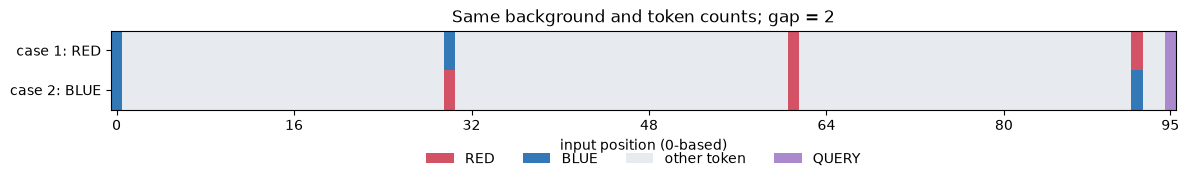

In [7]:
# 2, 24, 72 중 하나를 선택해 같은 빈도 & 배경의 두 예시를 살펴봅시다.
# OBSERVE_GAP 은 하단의 예시에서만 사용됩니다.
OBSERVE_GAP = 2
show_sequence_pair(data["train"], OBSERVE_GAP)

**Q8.** 출력된 자료의 shape와 두 입력 예시를 살펴봅시다.  
입력과 정답의 각 축은 무엇을 뜻하나요?

추가로, 두 예시에서 token의 빈도와 정답을 비교해봅시다.  
이 문제를 풀려면 왜 순서를 참고해야 하며, 마지막 지시와 질문 사이에는 어떤 정보를 유지해야 할까요?

그 외에도 어떻게 데이터가 저장되어있고, 표현되어있는지 자유롭게 살펴보고 정리해봅시다.

**이번 데이터는 96개의 토큰으로 이루어진 시퀀스를 입력받아 마지막 색상 지시가 빨강인지 파랑인지 분류하는 문제다.
빨강과 파랑은 동일한 횟수로 등장하므로 빈도만으로는 정답을 구할 수 없다. 모델은 색상 지시가 등장한 순서를 파악하고, 마지막으로 등장한 색상을 질문 시점까지 유지해야 한다.
이를 통해 RNN, LSTM, GRU가 이전 정보를 얼마나 효과적으로 기억하고 새로운 정보로 갱신하는지 비교할 수 있다.**


<a id="keras-model"></a>
## Keras로 공통 모델 만들기

이번에는 세 모델에 같은 입력과 출력을 사용해봅시다.

```text
토큰 ID 96개 → Embedding(차원 8)
            → SimpleRNN 또는 LSTM 또는 GRU(hidden 크기 32)
            → Dense(2, softmax) → 빨강/파랑 확률
```

Embedding으로 바꾼 벡터들을 순환층이 순서대로 읽고, 마지막 출력 벡터를 Dense 층에 전달합니다.  
`return_sequences=False`가 기본값이므로, 여기서는 시퀀스 전체에 대해 마지막 출력 벡터 하나를 받습니다.

**Q9.** 아래 함수의 두 TODO를 완성하여 세 모델을 연결해봅시다.

1. `layer_classes[model_type]`으로 선택한 순환층을 `config["units"]` 크기로 만들고, `x`에 적용해봅시다.
2. 그 결과에 `Dense(2, activation="softmax")`를 적용하여 두 색의 확률을 만들어봅시다.

**HINT:** 아래 문서에서 각 순환층의 사용 예시를 확인해봅시다. 공통으로 사용하는 부분과 모델에 따라 달라지는 부분을 찾아보면 도움이 될 겁니다.

각 모델에 대한 사용법 참고
* [SimpleRNN](https://keras.io/api/layers/recurrent_layers/simple_rnn/) 
* [LSTM](https://keras.io/api/layers/recurrent_layers/lstm/)
* [GRU](https://keras.io/api/layers/recurrent_layers/gru/)


In [9]:
def build_sequence_model(model_type, config):
    layer_classes = {
        "RNN": keras.layers.SimpleRNN,
        "LSTM": keras.layers.LSTM,
        "GRU": keras.layers.GRU,
    }

    inputs = keras.Input(
        shape=(config["sequence_length"],),
        dtype="int32"
    )

    x = keras.layers.Embedding(
        input_dim=len(TOKENS),
        output_dim=config["embedding_dim"],
        mask_zero=False
    )(inputs)

    # TODO 1: 선택한 순환층을 x에 적용
    recurrent_output = layer_classes[model_type](
        units=config["units"]
    )(x)

    # TODO 2: 두 클래스(빨강, 파랑)의 확률 생성
    outputs = keras.layers.Dense(
        2,
        activation="softmax"
    )(recurrent_output)

    if recurrent_output is None or outputs is None:
        return None

    return keras.Model(
        inputs,
        outputs,
        name=model_type.lower()
    )

### 채점머신 - Q9

모델을 연결했다면 아래 셀로 확인해봅시다.  
지정한 순환층을 사용하는지, 입력과 출력의 shape가 맞는지, 출력이 두 클래스의 확률인지 확인합니다.

이 단계에서는 모델의 연결을 점검합니다. **학습 정확도는 채점하지 않습니다.**  
TODO가 남아 있다면 안내를 확인한 뒤, 함수 정의 셀과 이 셀을 다시 실행해봅시다.


In [11]:
MODEL_READY = check_model_builder(build_sequence_model, CONFIG)
if MODEL_READY:
    example_model = build_sequence_model("RNN", CONFIG)
    example_model.summary()

🎉 세 모델의 순환층·입출력·확률 출력을 확인했습니다. 정확도는 채점하지 않습니다.


Model: "rnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_7 (Embedding)         │ (None, 96, 8)          │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,466 (5.73 KB)

 Trainable params: 1,466 (5.73 KB)

 Non-trainable params: 0 (0.00 B)

<a id="observe"></a>
## 모델 비교하기

같은 문제를 풀더라도, 세 모델이 학습하는 과정까지 같을까요?  
마지막 정확도가 비슷하다면 다른 부분에서도 차이를 찾아볼 수 있을 겁니다.

**Q10.** 지금까지 배운 개념을 바탕으로 어떤 항목을 관찰하면 효과적일지 예측해보고, 이유도 함께 정리해주세요.
원한다면 다른 관찰 기준을 추가해도 좋습니다.

| 관찰 항목 | 생각해볼 질문 |
|---|---|
| 학습 & 검증 곡선 | 학습이 진행되는 과정과 안정성에 어떤 차이가 있을까요? |
| 거리별 정확도 | 필요한 정보를 더 오래 유지해야 할 때 결과가 어떻게 달라질까요? |
| 결과와 비용 | 비슷한 결과를 얻는 데 필요한 파라미터와 시간은 얼마나 될까요? |
| 동일 입력의 예측 확률 | 정답 여부가 같더라도 출력 확률에는 어떤 차이가 있을까요? |

어느 모델이 더 좋을지 순위를 예상하기보다, 결과에서 찾아볼 근거를 먼저 정해봅시다.

**RNN: 구조가 단순해 학습이 빠르게 진행될 수 있지만 긴 시퀀스에서는 기울기 소실로 인해 학습이 정체될 수있을것 같다.
LSTM: Cell State와 Gate를 사용해 장기 의존성 학습에 유리하지만 구조가 복잡해 계산 비용이 증가할 수 있을것이다.
GRU: LSTM보다 상대적으로 단순한 게이트 구조를 사용하므로 계산 비용이 적으면서도 장기 의존성을 학습할 수 있다.
Gap이 증가할수록 마지막 색상 지시를 더 오래 기억해야 한다.
기본 RNN은 먼 과거의 정보를 학습하는 데 어려움을 겪을 가능성이 있지만 LSTM과 GRU는 게이트를 통해 필요한 정보를 선택적으로 유지할 수 있다.
일반적으로 RNN은 가장 적은 파라미터를 사용하고 GRU와 LSTM은 게이트 연산으로 인해 더 많은 파라미터를 필요로 한다.
따라서 정확도가 비슷하다면 더 적은 파라미터와 짧은 학습 시간으로 결과를 얻는 모델이 효율적일 수 있다.**

## 같은 조건으로 학습하기

관찰할 항목을 정했다면 세 모델을 학습해봅시다.  
매 모델에 같은 학습·검증 자료와 데이터 순서를 사용하고, optimizer는 각각 새로 만듭니다.  
구체적인 공통 설정은 다음과 같습니다.

| 항목 | 공통 설정 |
|---|---|
| Train / validation / test | 2,400 / 600 / 1,200개, 서로 다른 배경 그룹 |
| Embedding / hidden 크기 | 8 / 32 |
| Optimizer / learning rate | Adam / 0.001 |
| Batch / epoch / seed | 64 / 8 / 42 |
| Loss / 출력 | Sparse categorical cross-entropy / softmax 확률 2개 |
| Gradient clipping | `clipnorm=1.0` |

세 모델의 hidden 크기는 같지만, gate 구조가 달라 파라미터 수에는 차이가 생깁니다.  
학습 후 실제 파라미터 수와 실행 시간을 함께 확인해봅시다.  
같은 seed를 사용하더라도 구조가 다르면 초기 가중치 전체가 같아지는 것은 아닙니다.

Gradient clipping은 gradient가 지나치게 커지는 것을 완화하기 위한 공통 설정입니다.  
앞에서 살펴본 gradient 소실이나 정보 보존의 어려움은 별도로 생각해야 합니다.

아래 제공된 코드로 학습을 진행해봅시다.


In [12]:
comparison = None
test_results = None
if MODEL_READY:
    comparison = train_comparison(build_sequence_model, data, CONFIG)
else:
    print("Q9를 완성하고 자기점검 셀을 다시 실행해주세요.")


===== RNN / seed 42 =====
Epoch 1/8
38/38 - 2s - 60ms/step - accuracy: 0.6571 - loss: 0.6274 - val_accuracy: 0.8500 - val_loss: 0.4938
Epoch 2/8
38/38 - 1s - 16ms/step - accuracy: 0.9542 - loss: 0.3681 - val_accuracy: 1.0000 - val_loss: 0.2135
Epoch 3/8
38/38 - 1s - 16ms/step - accuracy: 1.0000 - loss: 0.1151 - val_accuracy: 1.0000 - val_loss: 0.0452
Epoch 4/8
38/38 - 1s - 19ms/step - accuracy: 1.0000 - loss: 0.0269 - val_accuracy: 1.0000 - val_loss: 0.0133
Epoch 5/8
38/38 - 0s - 8ms/step - accuracy: 1.0000 - loss: 0.0093 - val_accuracy: 1.0000 - val_loss: 0.0063
Epoch 6/8
38/38 - 0s - 9ms/step - accuracy: 1.0000 - loss: 0.0050 - val_accuracy: 1.0000 - val_loss: 0.0039
Epoch 7/8
38/38 - 0s - 9ms/step - accuracy: 1.0000 - loss: 0.0033 - val_accuracy: 1.0000 - val_loss: 0.0027
Epoch 8/8
38/38 - 0s - 9ms/step - accuracy: 1.0000 - loss: 0.0024 - val_accuracy: 1.0000 - val_loss: 0.0021

===== LSTM / seed 42 =====
Epoch 1/8
38/38 - 2s - 53ms/step - accuracy: 0.5638 - loss: 0.6878 - val_accu

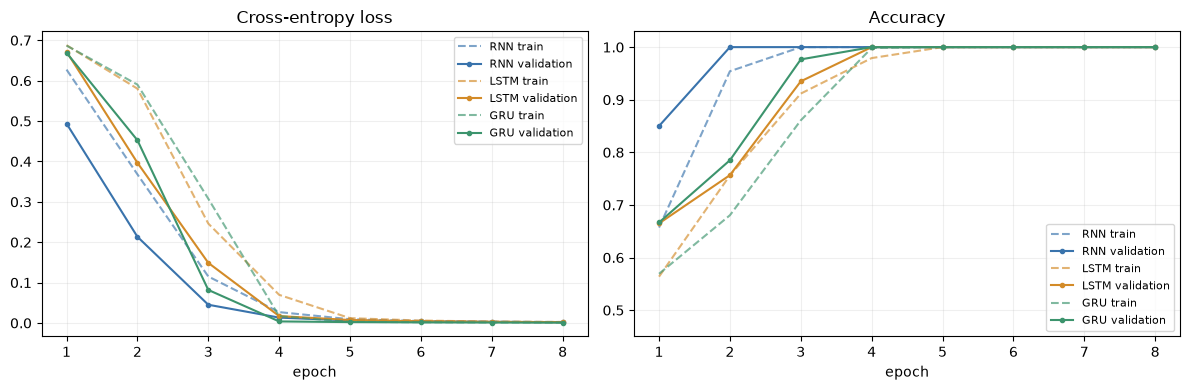

모델,parameter 수,학습 실행 시간(초),마지막 validation accuracy,마지막 validation loss
RNN,"1,466",5.59,1.000,0.0021
LSTM,"5,402",6.94,1.000,0.0021
GRU,"4,186",9.32,1.000,0.0009


In [13]:
if comparison is not None:
    plot_learning_curves(comparison)
    show_training_summary(comparison)
else:
    print("모델 학습 후 그래프와 표를 확인할 수 있습니다.")

학습이 끝났다면 Q10에서 생각한 항목을 확인해봅시다.  
곡선이 어느 구간에서 어떻게 달라지는지, 비슷한 정확도에 도달하는 과정에도 차이가 있는지 살펴봅시다.  
차이가 작거나 관찰되지 않은 부분도 그대로 기록하면 됩니다.

표의 시간은 `fit` 전체를 측정한 값입니다. 첫 실행 준비와 epoch별 학습, validation이 함께 포함됩니다.  
아래에 자유롭게 결과를 정리해봅시다.

**이번 실험에서는 기본 RNN도 LSTM과 GRU에 뒤처지지 않았으며, 오히려 더 적은 파라미터와 짧은 학습 시간으로 높은 정확도에 도달했다.
이는 LSTM과 GRU가 장기 의존성 학습에 유리한 구조를 가지고 있더라도 모든 문제에서 반드시 RNN보다 좋은 성능을 보이는 것은 아니라는 점을 보여준다.
이번 색상 기억 문제는 마지막 색상 지시를 유지하는 비교적 명확한 규칙을 가지고 있으므로, 기본 RNN도 해당 규칙을 효과적으로 학습했을 가능성이 있다.
따라서 현재 결과에서는 RNN이 계산 효율성 측면에서 유리했으며, LSTM과 GRU의 구조적 장점이 뚜렷한 정확도 차이로 나타나지는 않았다.**

<a id="test-results"></a>
## Test와 거리별 결과 확인하기

이번에는 학습에 사용하지 않은 test 자료에서 결과를 확인해봅시다.  
전체 정확도와 함께 gap별 정확도, 같은 입력에 대한 예측 확률도 살펴봅시다.

앞에서 정한 학습 조건과 관찰 기준으로 최종 결과를 비교합니다.  
Test 결과를 보고 설정을 반복해서 바꾸면, 그 자료도 선택 과정에 사용하게 된다는 점을 떠올려봅시다.

여기서 gap별 결과는 **학습에서 함께 본 거리 조건을 새로운 자료에서도 처리하는지** 살펴보는 것입니다.  

모델,test accuracy,test loss,gap=2 accuracy,gap=24 accuracy,gap=72 accuracy
RNN,1.000,0.0021,1.000,1.000,1.000
LSTM,1.000,0.0021,1.000,1.000,1.000
GRU,1.000,0.0009,1.000,1.000,1.000


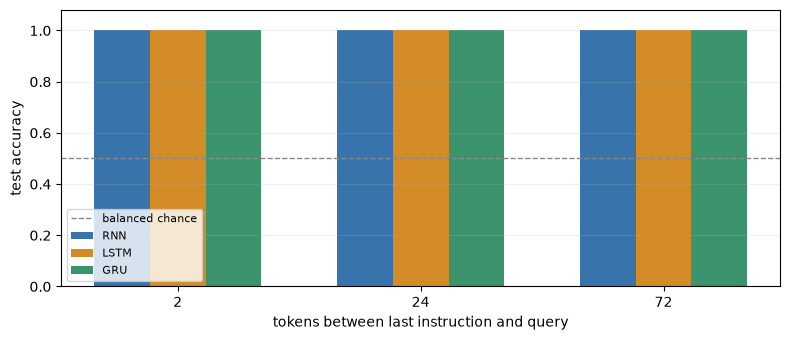

In [14]:
if comparison is not None:
    test_results = evaluate_comparison(comparison, data["test"])
    show_test_summary(test_results, comparison["config"]["gaps"])
else:
    print("모델 학습 후 test를 평가할 수 있습니다.")

In [15]:
if test_results is not None:
    show_prediction_pair(test_results, data["test"], OBSERVE_GAP)
else:
    print("Test 평가 후 동일 입력의 예측 확률을 확인할 수 있습니다.")

입력,정답,RNN,LSTM,GRU
예시 1,빨강,"P(빨강)=0.99798, P(파랑)=0.00202","P(빨강)=0.99630, P(파랑)=0.00370","P(빨강)=0.99844, P(파랑)=0.00156"
예시 2,파랑,"P(빨강)=0.00417, P(파랑)=0.99583","P(빨강)=0.01056, P(파랑)=0.98944","P(빨강)=0.00202, P(파랑)=0.99798"


**Q11.** Q10에서 생각한 항목을 중심으로, 관찰한 결과를 정리해봅시다.

* 그래프에서 특이한 점은 없었나요? 있었다면 왜 특이하다고 느꼈고, 왜 그런 현상이 발생했을까요?
* 성능만 보지 말고, 어떻게 학습했는지도 살펴봅시다. 학습 과정이 안정적이었나요? 학습 시간은 어땠나요?
* 만약 이 문제를 해결할 1개의 모델을 고른다면 어떤 모델을 고를 것이며, 왜 그 모델인가요?
* 각 모델의 의도(탄생 배경) 과 결과가 잘 일치하나요? 특히 LSTM 과 GRU 는 비슷한 점이 많은데, 어떤 차이를 보이나요?

세 모델이 같은 정확도에 도달할 수도 있습니다. 대신에 과정과 비용에 어떤 차이가 있나 확인해봅시다.

**이번 실험에서는 동일한 데이터와 학습 조건에서 RNN, LSTM, GRU의 성능을 비교하였다.
세 모델 모두 최종 테스트 정확도 100%를 달성했으며 Gap이 2, 24, 72로 증가해도 정확도가 감소하지 않았다. 이는 세 모델 모두 마지막 색상 지시를 기억하는 규칙을 효과적으로 학습했음을 보여준다.
학습 과정에서는 RNN이 가장 빠르게 검증 정확도 100%에 도달했으며, 파라미터 수도 1,466개로 가장 적었다. 반면 LSTM과 GRU는 각각 5,402개와 4,186개의 파라미터를 사용했다. GRU는 가장 낮은 테스트 손실인 0.0009를 기록했지만, 학습 시간은 가장 길었다.
일반적으로 LSTM과 GRU는 게이트 구조를 통해 장기 의존성 학습에 유리하지만, 이번 실험에서는 기본 RNN도 Gap 72까지 정확하게 처리했다. 따라서 모델의 구조가 복잡하다고 반드시 더 좋은 결과를 얻는 것은 아니며 문제의 특성과 학습 조건에 따라 단순한 모델이 더 효율적일 수 있다는 점을 확인할 수 있었다.**


### 다른 seed의 결과도 살펴볼까요? - 선택 참고

지금까지의 관찰을 먼저 정리했다면, 실행을 바꾸어도 비슷한 모습이 나오는지 살펴봅시다.  
아래는 같은 코드와 학습 조건에서 seed를 42, 43, 44로 바꾸어 실행한 제작자의 기록입니다.

자신의 결과와 비교하면서 반복해서 나타나는 모습과 달라지는 부분을 찾아봅시다.  
제공된 기록을 참고하면 되며, 같은 수치를 얻거나 세 번 다시 학습할 필요는 없습니다.  
실행 환경에 문제가 있다면 이 기록과 다음의 학습 곡선을 관찰 자료로 사용할 수도 있습니다.

In [16]:
show_reference_summary(WEEK5 / "reference_results.json")

seed,모델,parameter,validation accuracy,test accuracy,gap: accuracy
42,RNN,1466,1.000,1.000,"2:1.000, 24:1.000, 72:1.000"
42,LSTM,5402,1.000,1.000,"2:1.000, 24:1.000, 72:1.000"
42,GRU,4186,1.000,1.000,"2:1.000, 24:1.000, 72:1.000"
43,RNN,1466,1.000,1.000,"2:1.000, 24:1.000, 72:1.000"
43,LSTM,5402,1.000,1.000,"2:1.000, 24:1.000, 72:1.000"
43,GRU,4186,1.000,1.000,"2:1.000, 24:1.000, 72:1.000"
44,RNN,1466,1.000,1.000,"2:1.000, 24:1.000, 72:1.000"
44,LSTM,5402,1.000,1.000,"2:1.000, 24:1.000, 72:1.000"
44,GRU,4186,1.000,1.000,"2:1.000, 24:1.000, 72:1.000"


제작자 환경: {'python': '3.12.11', 'platform': 'Darwin', 'machine': 'arm64', 'tensorflow': '2.21.0', 'keras': '3.15.1', 'device': 'CPU', 'timing_scope': 'fit wall time, including tracing and validation; excluding import and test prediction'} 
이 결과의 순위나 수치에 맞출 필요는 없습니다.


아래는 **제작자의 seed 42 실행**에서 얻은 학습 곡선입니다.  
자신의 실행 결과와 구분하여 살펴봅시다.

<img src="./imgs/reference_learning.png" width="950" alt="제작자의 seed 42 실행에서 얻은 RNN·LSTM·GRU 학습·검증 곡선">


<a id="wrap-up"></a>
# 7. 마무리

이번에는 언어의 특성에서 출발하여, 앞의 정보를 참고하고 유지하는 여러 방법을 살펴보았습니다.  
각 방법이 어떤 어려움을 줄이고자 했는지 다시 정리해봅시다.

| 살펴본 어려움 | 이를 다루는 방법 | 이어서 생각해볼 질문 |
|---|---|---|
| N-gram의 정해진 문맥 범위와 관측하기 어려운 조합 | RNN으로 앞의 정보를 상태에 반영하여 전달 | 먼 과거의 정보를 오래 유지하도록 학습할 수 있을까요? |
| 기본 RNN의 장기 의존성 학습 | LSTM & GRU로 정보의 보존과 갱신을 조절 | 입력을 순서대로 처리하는 과정과 상태의 크기는 어떤 부담을 만들까요? |
| 입력과 다른 길이 & 순서의 문장 만들기 | Encoder와 decoder를 연결한 seq2seq | 필요한 정보를 일정한 크기의 context에 담아 전달할 수 있을까요? |
| Seq2seq의 정보 압축 병목 | Attention으로 출력마다 입력 표현을 다시 참조 | 이런 참조 계산을 중심으로 다른 구조를 만들 수도 있을까요? |

이때 N-gram은 확률을 구하는 방법, RNN & LSTM & GRU는 순환 구조, seq2seq는 입력과 출력을 연결하는 구성, attention은 정보를 참조하는 기법입니다.  
서로 함께 사용할 수도 있다는 점을 떠올리며, 각 방법이 맡는 역할을 구분해봅시다.

<a id="references"></a>
## 참고자료

본문의 예시를 먼저 살펴보고, 수업 내용을 복습하거나 설명을 보완하고 싶을 때 아래 자료를 참고해봅시다.  
문서 확인을 요청한 문항에서는 해당 문서를 살펴보고 자신의 말로 정리하면 됩니다.  
아래 영상은 필요한 부분을 찾아서 참고해도 좋습니다.

- [CS224N 5강: Recurrent Neural Networks](https://www.youtube.com/watch?v=fyc0Jzr74y4)
- [CS224N 6강: Sequence to Sequence Models](https://www.youtube.com/watch?v=Ba6Fn1-Jsfw)
- [MIT Vision Book: Transformers](https://visionbook.mit.edu/transformers.html) — attention의 도입 의도 참고
- [Words and Tokens](https://web.stanford.edu/~jurafsky/slp3/2.pdf)
- [N-gram Language Models](https://web.stanford.edu/~jurafsky/slp3/3.pdf)